# COVERTYPE — CHỌN ĐẶC TRƯNG BẰNG MUTUAL INFORMATION CHO LR VÀ RF
Notebook thí nghiệm mới, chưa có kết quả huấn luyện. Bản gốc `LR_RF_Covertype.ipynb` giữ nguyên output.

**54 đặc trưng đầu vào + 1 nhãn = 55 cột**, không phải 55 đặc trưng.
Dùng cùng split 80/20, seed42, 3-fold và lưới 16 cấu hình mỗi mô hình như bản gốc.
Chọn cố định top20 bằng Mutual Information trong từng fold trước khi huấn luyện LR/RF; không PCA.
Số 20 định trước, không chọn theo Test. Không bảo đảm cải thiện kết quả.

Run All có thể mất nhiều giờ. Kết quả và cache nằm riêng trong
`Covertype_RF_LR_MI/runs/<timestamp>/`.


### Chuẩn bị thư viện
Nếu môi trường thiếu thư viện, chạy `%pip install ucimlrepo numpy pandas matplotlib seaborn scikit-learn joblib threadpoolctl`.
Import trước để các cell dữ liệu chạy được; phần 4 tổng hợp lại môi trường.
Requires scikit-learn >= 1.5 for mutual_info_classif(n_jobs=...).


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from pathlib import Path
from datetime import datetime
from time import perf_counter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

SEED = 42
N_SPLITS = 3
N_JOBS = 2
import re
from functools import partial
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.compose import make_column_selector
from joblib import Memory

TOP_K = 20
RESULTS_ROOT = Path('Covertype_RF_LR_MI')
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT = RESULTS_ROOT / 'runs' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
memory = Memory(location=str(OUT / 'pipeline_cache'), verbose=0)
print('Thư mục thực nghiệm mới:', OUT.resolve())


Thư mục thực nghiệm mới: /content/Covertype_RF_LR_MI/runs/20261114_131410_269979


## 1. Bộ dữ liệu đầu vào
Covertype gồm **581.012 mẫu, 54 đặc trưng, 7 lớp**. Tải trực tiếp từ UCI bằng
`fetch_ucirepo(id=31)`, giống cách nạp dữ liệu trong bài thực hành.
Nguồn đã có tên cột; sau khi tải mới phân nhóm cột. Không one-hot lại 44 cột nhị phân.

In [6]:
# Nếu thiếu thư viện, bỏ dấu # dòng sau và chạy một lần.
%pip install ucimlrepo numpy pandas matplotlib seaborn scikit-learn joblib threadpoolctl


In [7]:
from ucimlrepo import fetch_ucirepo

covertype = fetch_ucirepo(id=31)
X = covertype.data.features.astype(np.float32)
y = covertype.data.targets.squeeze().astype(np.int8)

df = X.copy()
df['Cover_Type'] = y
print('Kích thước:', df.shape)
display(df.head())
df.info()

Kích thước: (581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           581012 non-null  float32
 1   Aspect                              581012 non-null  float32
 2   Slope                               581012 non-null  float32
 3   Horizontal_Distance_To_Hydrology    581012 non-null  float32
 4   Vertical_Distance_To_Hydrology      581012 non-null  float32
 5   Horizontal_Distance_To_Roadways     581012 non-null  float32
 6   Hillshade_9am                       581012 non-null  float32
 7   Hillshade_Noon                      581012 non-null  float32
 8   Hillshade_3pm                       581012 non-null  float32
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  float32
 10  Wilderness_Area1                    581012 non-null  float32
 11  Soil_Type1                

In [8]:
cot_vung_rung = [c for c in X.columns if c.startswith('Wilderness_Area')]
cot_loai_dat = [c for c in X.columns if c.startswith('Soil_Type')]
cot_nhi_phan = cot_vung_rung + cot_loai_dat
cot_so = [c for c in X.columns if c not in cot_nhi_phan]
features = X.columns.tolist()
class_names = ['Spruce/Fir', 'Lodgepole Pine', 'Ponderosa Pine',
               'Cottonwood/Willow', 'Aspen', 'Douglas-fir', 'Krummholz']
labels = np.arange(1, 8)
print('Số cột số:', len(cot_so), '| Số cột nhị phân:', len(cot_nhi_phan))
assert len(cot_so) == 10 and len(cot_vung_rung) == 4 and len(cot_loai_dat) == 40

Số cột số: 10 | Số cột nhị phân: 44


## 2. Khảo sát và phân tích dữ liệu (EDA)
Kiểm tra chất lượng nguồn. Để giữ Test độc lập, tách holdout ngay trước EDA;
các biểu đồ và thống kê mô tả bên dưới dùng **Train**. Phần 3 giải thích và kiểm tra cách chia.

In [9]:
print('Tổng ô thiếu:', df.isnull().sum().sum())
print('Số dòng trùng:', df.duplicated().sum())
assert df.shape == (581012, 55)
assert np.array_equal(np.sort(df['Cover_Type'].unique()), labels)
assert np.isfinite(df[features].to_numpy()).all()
assert df[cot_nhi_phan].isin([0, 1]).all().all()
assert df[cot_vung_rung].sum(axis=1).eq(1).all(), 'Nhóm Wilderness_Area không hợp lệ.'
assert df[cot_loai_dat].sum(axis=1).eq(1).all(), 'Nhóm Soil_Type không hợp lệ.'

Tổng ô thiếu: 0
Số dòng trùng: 0


In [10]:
X = df[features]
y = df['Cover_Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (464809, 54) | Test: (116203, 54)


### 2.1. Thống kê mô tả và phân bố 7 lớp

,count,mean,std,min,25%,50%,75%,max
Elevation,464809.0,2959.510254,279.988647,1860.0,2809.0,2996.0,3164.0,3858.0
Aspect,464809.0,155.828568,111.968201,0.0,58.0,127.0,261.0,360.0
Slope,464809.0,14.104561,7.486888,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,464809.0,269.348358,212.376556,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,464809.0,46.420753,58.232655,-166.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,464809.0,2351.818115,1559.205444,0.0,1106.0,1999.0,3331.0,7117.0
Hillshade_9am,464809.0,212.130142,26.761314,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,464809.0,223.316498,19.764175,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,464809.0,142.546127,38.265263,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,464809.0,1979.968018,1323.535400,0.0,1024.0,1710.0,2550.0,7172.0


,Tên lớp,Số mẫu Train,Tỷ lệ (%)
Cover_Type,,,
1,Spruce/Fir,169472,36.460568
2,Lodgepole Pine,226640,48.759813
3,Ponderosa Pine,28603,6.153710
4,Cottonwood/Willow,2198,0.472882
5,Aspen,7594,1.633789
6,Douglas-fir,13894,2.989185
7,Krummholz,16408,3.530052


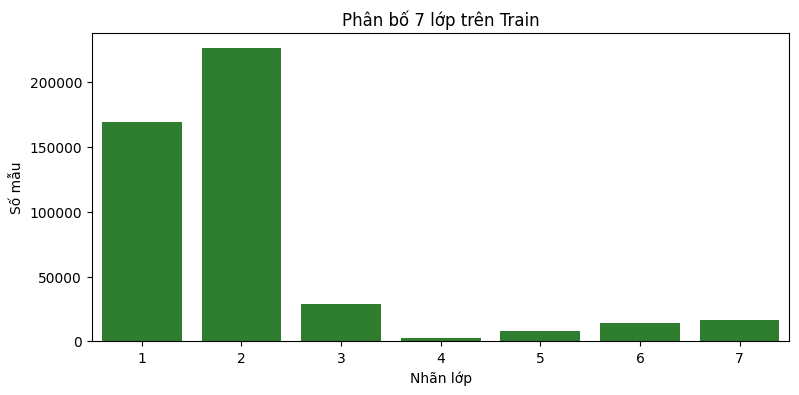

In [11]:
display(X_train[cot_so].describe().T)

counts = y_train.value_counts().sort_index()
distribution = pd.DataFrame({'Tên lớp': class_names, 'Số mẫu Train': counts,
                              'Tỷ lệ (%)': counts / len(y_train) * 100})
display(distribution)

plt.figure(figsize=(9, 4))
sns.countplot(x=y_train, color='forestgreen')
plt.title('Phân bố 7 lớp trên Train')
plt.xlabel('Nhãn lớp')
plt.ylabel('Số mẫu')
plt.show()

### 2.2. Phân bố đặc trưng, tương quan và độ cao theo lớp

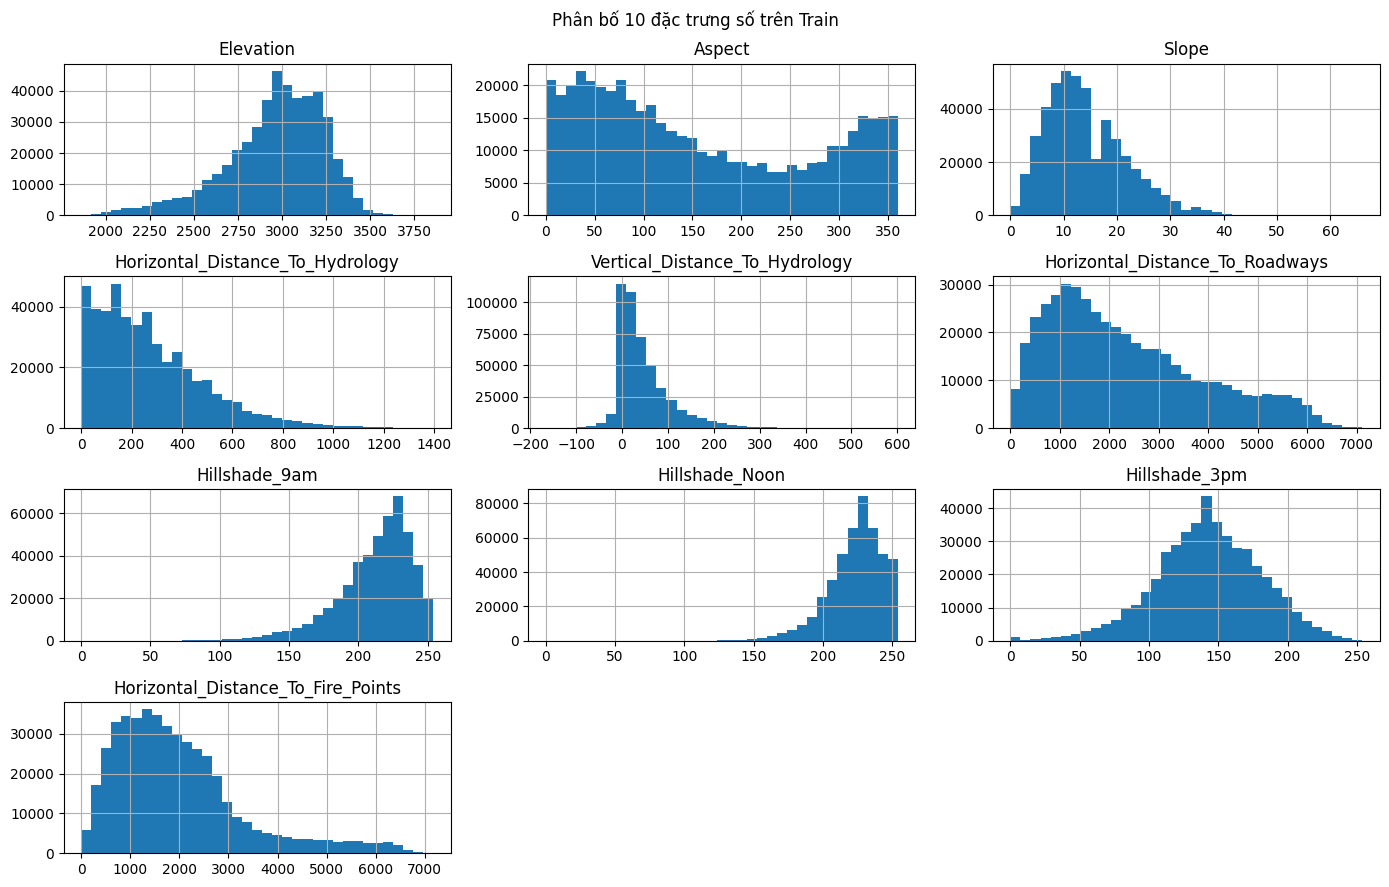

In [12]:
X_train[cot_so].hist(bins=35, figsize=(14, 9))
plt.suptitle('Phân bố 10 đặc trưng số trên Train')
plt.tight_layout()
plt.show()

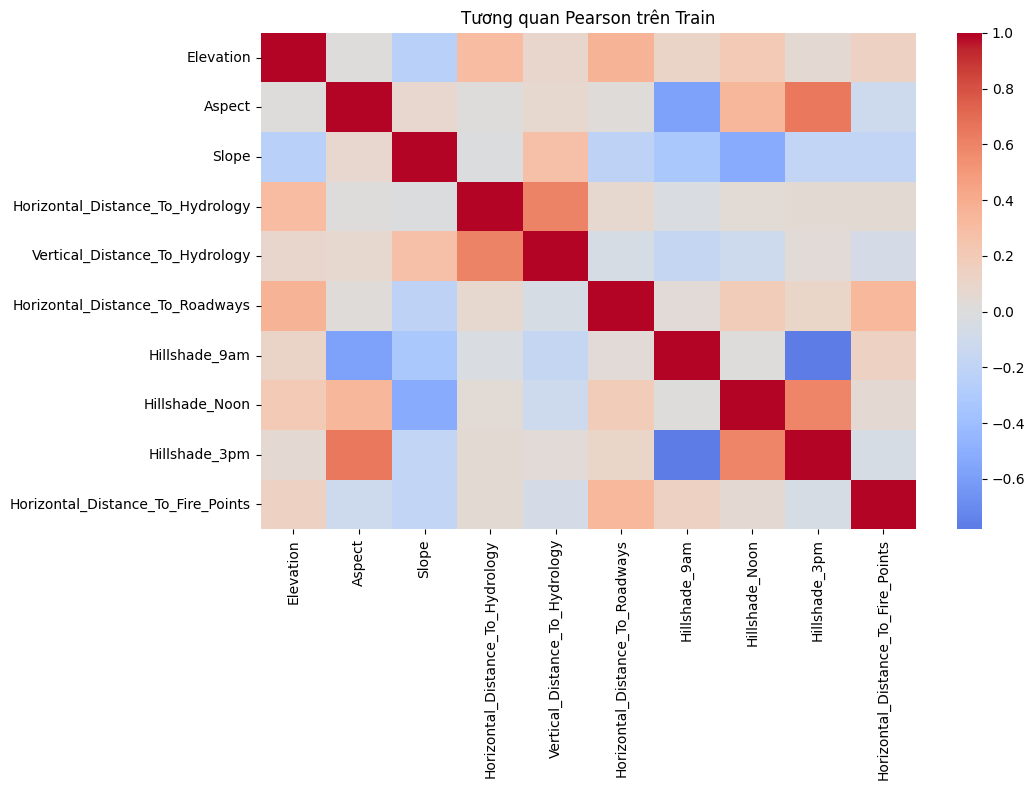

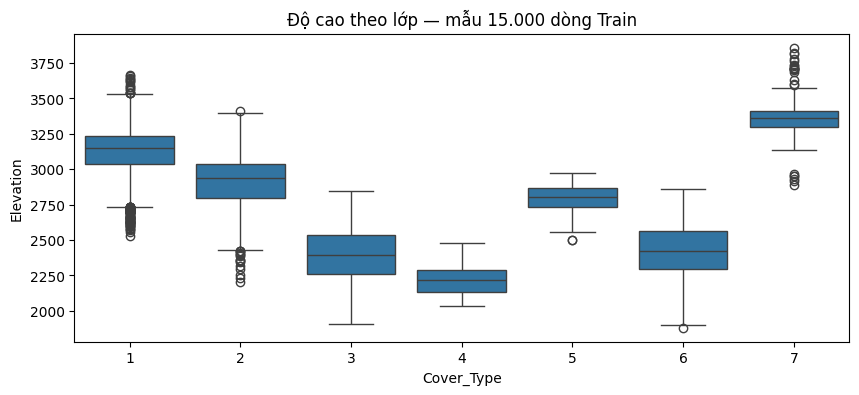

In [13]:
plt.figure(figsize=(11, 8))
sns.heatmap(X_train[cot_so].corr(), cmap='coolwarm', center=0)
plt.title('Tương quan Pearson trên Train')
plt.tight_layout()
plt.show()

sample = X_train[['Elevation']].assign(Cover_Type=y_train).sample(15000, random_state=SEED)
plt.figure(figsize=(10, 4))
sns.boxplot(data=sample, x='Cover_Type', y='Elevation')
plt.title('Độ cao theo lớp — mẫu 15.000 dòng Train')
plt.show()

## 3. Tiền xử lý và chia dữ liệu
Holdout 80/20, phân tầng theo y, seed=42: **464.809 Train / 116.203 Test**.
LR và RF dùng đúng các biến Train/Test đã tạo, không chia lại riêng từng mô hình.
Không xóa trùng/ngoại lệ cơ học và không resampling. Tiền xử lý học tham số đặt trong Pipeline.

In [14]:
train_idx = X_train.index.to_numpy(dtype=np.int64)
test_idx = X_test.index.to_numpy(dtype=np.int64)
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(train_idx) + len(test_idx) == len(df)

# Đối chiếu chỉ số với split đã lưu nếu có; không ghi đè phiên cũ.
split_path = Path('Covertype_RF_LR/shared_split.npz')
if split_path.exists():
    with np.load(split_path, allow_pickle=False) as split:
        np.testing.assert_array_equal(train_idx, split['train_idx'])
        np.testing.assert_array_equal(test_idx, split['test_idx'])

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(skf.split(X_train, y_train))
print('Hai mô hình dùng chung', len(cv_splits), 'fold trên toàn bộ Train.')

Hai mô hình dùng chung 3 fold trên toàn bộ Train.


## 4. Công cụ và thư viện
Python/scikit-learn xử lý trên một máy; pandas/NumPy quản lý dữ liệu,
matplotlib/seaborn vẽ biểu đồ. Dùng `perf_counter` đo thời gian trực tiếp.

In [15]:
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('Seed:', SEED, '| CV:', N_SPLITS, 'fold | Giới hạn luồng:', N_JOBS)

scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.4.6
Seed: 42 | CV: 3 fold | Giới hạn luồng: 2


## 5. Chọn đặc trưng bằng Mutual Information trong Pipeline
MI chấm mức phụ thuộc giữa từng đặc trưng và nhãn, không dùng LR/RF để chấm điểm.
Giữ TOP_K=20 cố định; đây là cấu hình thử nghiệm, chưa phải số biến tối ưu.
10 biến số được xử lý theo bộ ước lượng liên tục; 44 biến nhị phân được khai báo rời rạc
bằng mask theo đúng thứ tự tên cột UCI, không giả định chúng nằm liền nhau.

MI chỉ học trên phần Train của từng fold. Hai mô hình dùng cùng selector, seed và fold,
nên dùng cùng bộ biến trong mỗi fold; tập biến có thể khác giữa các fold.
Cache tái sử dụng điểm MI trên đúng dữ liệu/tham số, không dùng Test.
MI đánh giá từng biến riêng, có thể bỏ qua tương tác hoặc giữ các biến trùng thông tin.
MI không phụ thuộc mô hình phân loại, nhưng không bảo đảm lợi ích ngang nhau cho LR và RF.

### 5.1. MI selector → tiền xử lý → Logistic Regression
Selector trả DataFrame để giữ tên cột. Chỉ chuẩn hóa biến số còn lại; biến nhị phân giữ nguyên.


In [16]:
# Mask theo tên cột, tương ứng chính xác với thứ tự X đầu vào.
discrete_mask = np.array([c in cot_nhi_phan for c in features], dtype=bool)
assert discrete_mask.sum() == 44 and (~discrete_mask).sum() == 10
mi_score_func = partial(mutual_info_classif, discrete_features=discrete_mask,
                        n_neighbors=3, random_state=SEED, n_jobs=N_JOBS)
selector = SelectKBest(score_func=mi_score_func, k=TOP_K).set_output(transform='pandas')
assert 0 < TOP_K < len(features)

pipeline_so = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
pipeline_nhi_phan = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))
])
# Chọn theo tên cột sau selector.
preprocessor = ColumnTransformer([
    ('so', pipeline_so, make_column_selector(pattern='^(?:' + '|'.join(map(re.escape, cot_so)) + ')$')),
    ('nhi_phan', pipeline_nhi_phan, make_column_selector(pattern='^(?:' + '|'.join(map(re.escape, cot_nhi_phan)) + ')$'))
])
pipe_lr = Pipeline([
    ('select', clone(selector)),
    ('prep', preprocessor),
    ('clf', LogisticRegression(C=1.0, class_weight=None, solver='lbfgs',
                               max_iter=1000, random_state=SEED))
], memory=memory)
pipe_lr

Pipeline(memory=Memory(location=Covertype_RF_LR_MI/runs/20261114_131410_269979/pipeline_cache/joblib),
         steps=[('select',
                 SelectKBest(k=20,
                             score_func=functools.partial(<function mutual_info_classif at 0x79edd1b76a20>, discrete_features=array([False, False, False, False, False, False, False, False, False,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True...
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x79edc7dbaa50>),
                                                 ('nhi_phan',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x79edca222c10>)])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

### 5.2. MI selector → Random Forest
RF phân loại nhận TOP_K biến do cùng phương pháp MI lựa chọn, không chuẩn hóa.
Không huấn luyện RF để chọn biến. Feature Importance chỉ phân tích RF sau huấn luyện.


In [17]:
pipe_rf = Pipeline([
    ('select', clone(selector)),
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=None,
                                   max_features='sqrt', min_samples_leaf=1,
                                   class_weight=None, random_state=SEED, n_jobs=N_JOBS))
], memory=memory)
pipe_rf

Pipeline(memory=Memory(location=Covertype_RF_LR_MI/runs/20261114_131410_269979/pipeline_cache/joblib),
         steps=[('select',
                 SelectKBest(k=20,
                             score_func=functools.partial(<function mutual_info_classif at 0x79edd1b76a20>, discrete_features=array([False, False, False, False, False, False, False, False, False,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True]), n_neighbors=3, random_state=42, n_jobs=2))),
                ('clf', RandomForestClassifier(n_jobs=2, random_state=42))])

## 6. Tối ưu mô hình: Cross-Validation + Grid Search
Tương tự TH4: dùng `cross_validate` xem baseline, sau đó tạo `GridSearchCV` cho từng Pipeline.
Chọn cấu hình theo **Macro-F1 trên CV**; Test không tham gia tìm tham số.

### 6.1. Đánh giá chéo hai mô hình cơ sở có chọn đặc trưng
Cả baseline và mô hình tối ưu bên dưới đều dùng TOP_K; trước/sau ở đây là trước/sau tối ưu tham số.


In [18]:
models = {'LR': pipe_lr, 'RF': pipe_rf}
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
cv_baseline = {}
rows_cv = []

for name, model in models.items():
    with threadpool_limits(limits=N_JOBS):
        scores = cross_validate(model, X_train, y_train, cv=cv_splits,
                                 scoring=scoring, n_jobs=1, return_train_score=True,
                                 error_score='raise')
    cv_baseline[name] = scores
    rows_cv.append({'Mô hình': name,
                    'CV Macro-F1': scores['test_f1_macro'].mean(),
                    'Độ lệch chuẩn': scores['test_f1_macro'].std(),
                    'Train Macro-F1': scores['train_f1_macro'].mean()})

display(pd.DataFrame(rows_cv))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

,Mô hình,CV Macro-F1,Độ lệch chuẩn,Train Macro-F1
0,LR,0.506533,0.005425,0.507557
1,RF,0.906951,0.003149,0.999999


### 6.2. Grid Search cho LR
8 giá trị C × 2 lựa chọn class_weight = **16 cấu hình × 3 fold = 48 lượt CV**.
Solver lbfgs dùng L2. `refit=True` tự fit cấu hình tốt nhất trên toàn bộ Train.

In [19]:
param_grid_lr = {
    'clf__C': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
    'clf__class_weight': [None, 'balanced']
}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv_splits, scoring='f1_macro',
                       n_jobs=1, refit=True, return_train_score=True,
                       error_score='raise', verbose=2)

In [20]:
import warnings
from sklearn.exceptions import ConvergenceWarning

start = perf_counter()
with warnings.catch_warnings(), threadpool_limits(limits=N_JOBS):
    warnings.simplefilter('error', ConvergenceWarning)
    grid_lr.fit(X_train, y_train)
search_time_lr = perf_counter() - start

print('Tham số LR tốt nhất:', grid_lr.best_params_)
print('Macro-F1 CV LR:', grid_lr.best_score_)
print('Thời gian tìm kiếm LR:', round(search_time_lr, 2), 'giây')

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END ..............clf__C=0.0001, clf__class_weight=None; total time=   3.6s
[CV] END ..............clf__C=0.0001, clf__class_weight=None; total time=   4.3s
[CV] END ..............clf__C=0.0001, clf__class_weight=None; total time=   3.8s
[CV] END ..........clf__C=0.0001, clf__class_weight=balanced; total time=   3.5s
[CV] END ..........clf__C=0.0001, clf__class_weight=balanced; total time=   4.3s
[CV] END ..........clf__C=0.0001, clf__class_weight=balanced; total time=   3.9s
[CV] END ...............clf__C=0.001, clf__class_weight=None; total time=   7.2s
[CV] END ...............clf__C=0.001, clf__class_weight=None; total time=   6.3s
[CV] END ...............clf__C=0.001, clf__class_weight=None; total time=   7.9s
[CV] END ...........clf__C=0.001, clf__class_weight=balanced; total time=   6.7s
[CV] END ...........clf__C=0.001, clf__class_weight=balanced; total time=   6.6s
[CV] END ...........clf__C=0.001, clf__class_wei

In [21]:
df_grid_lr = pd.DataFrame(grid_lr.cv_results_).sort_values('rank_test_score')
display(df_grid_lr[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(5))

,params,mean_test_score,std_test_score,rank_test_score
14,"{'clf__C': 1000.0, 'clf__class_weight': None}",0.507573,0.004678,1
10,"{'clf__C': 10.0, 'clf__class_weight': None}",0.507490,0.005004,2
12,"{'clf__C': 100.0, 'clf__class_weight': None}",0.507273,0.005259,3
8,"{'clf__C': 1.0, 'clf__class_weight': None}",0.506533,0.005425,4
6,"{'clf__C': 0.1, 'clf__class_weight': None}",0.501714,0.005357,5


### 6.3. Grid Search cho RF

2 × 2 × 2 × 2 = **16 cấu hình × 3 fold = 48 lượt CV**, sau đó refit tốt nhất.

In [22]:
param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [20, None],
    'clf__max_features': ['sqrt', 0.5],
    'clf__min_samples_leaf': [1, 3]
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv_splits, scoring='f1_macro',
                       n_jobs=1, refit=True, return_train_score=True,
                       error_score='raise', verbose=2)

In [23]:
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    grid_rf.fit(X_train, y_train)
search_time_rf = perf_counter() - start

print('Tham số RF tốt nhất:', grid_rf.best_params_)
print('Macro-F1 CV RF:', grid_rf.best_score_)
print('Thời gian tìm kiếm RF:', round(search_time_rf, 2), 'giây')

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=100; total time=  39.0s
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=100; total time=  40.3s
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=100; total time=  42.9s
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=200; total time= 1.3min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=200; total time= 1.3min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=200; total time= 1.4min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=3, clf__n_estimators=100; total time=  39.1s
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=3, clf__n_estimators=100; total 

In [24]:
import pandas as pd
df_grid_rf = pd.DataFrame(grid_rf.cv_results_).sort_values('rank_test_score')
display(df_grid_rf[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(5))

,params,mean_test_score,std_test_score,rank_test_score
13,"{'clf__max_depth': None, 'clf__max_features': ...",0.926392,0.001509,1
12,"{'clf__max_depth': None, 'clf__max_features': ...",0.925726,0.001000,2
15,"{'clf__max_depth': None, 'clf__max_features': ...",0.915948,0.002079,3
14,"{'clf__max_depth': None, 'clf__max_features': ...",0.915489,0.002081,4
9,"{'clf__max_depth': None, 'clf__max_features': ...",0.907984,0.002578,5


## 7. Đánh giá và so sánh kết quả
### 7.1. Huấn luyện baseline và lấy mô hình tốt nhất
`cross_validate` chỉ fit bản sao trong các fold; cần fit lại hai baseline trên toàn bộ Train.
Hai mô hình tối ưu đã được Grid Search refit. Không chọn lại tham số theo Test.

In [25]:
lr_before = clone(pipe_lr)
start = perf_counter()
with warnings.catch_warnings(), threadpool_limits(limits=N_JOBS):
    warnings.simplefilter('error', ConvergenceWarning)
    lr_before.fit(X_train, y_train)
fit_time_lr = perf_counter() - start

rf_before = clone(pipe_rf)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    rf_before.fit(X_train, y_train)
fit_time_rf = perf_counter() - start

best_lr = grid_lr.best_estimator_
best_rf = grid_rf.best_estimator_
print('LR tối ưu:', grid_lr.best_params_)
print('RF tối ưu:', grid_rf.best_params_)

LR tối ưu: {'clf__C': 1000.0, 'clf__class_weight': None}
RF tối ưu: {'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}


### 7.2. Dự đoán trên Test

Đo predict 3 lần trên cùng Test, lấy trung vị cho cả bốn mô hình.

In [26]:
models = {'lr_before': lr_before, 'lr_after': best_lr,
          'rf_before': rf_before, 'rf_after': best_rf}
predictions = {}
predict_times = {}

for name, model in models.items():
    times = []
    with threadpool_limits(limits=N_JOBS):
        for repeat in range(3):
            start = perf_counter()
            y_pred = model.predict(X_test)
            times.append(perf_counter() - start)
    predictions[name] = y_pred
    predict_times[name] = float(np.median(times))

y_pred_lr = predictions['lr_after']
y_pred_rf = predictions['rf_after']

### 7.3. Đánh giá LR và RF tối ưu — gọi metric trực tiếp như TH4

In [27]:
print('LOGISTIC REGRESSION TỐI ƯU')
print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print('Precision macro:', precision_score(y_test, y_pred_lr, average='macro', zero_division=0))
print('Recall macro:', recall_score(y_test, y_pred_lr, average='macro', zero_division=0))
print('Macro-F1:', f1_score(y_test, y_pred_lr, average='macro', zero_division=0))
print(classification_report(y_test, y_pred_lr, labels=labels, target_names=class_names, zero_division=0))

LOGISTIC REGRESSION TỐI ƯU
Accuracy: 0.7165993993270398
Precision macro: 0.5549496338885557
Recall macro: 0.47668142477375913
Macro-F1: 0.5011781917679858
                   precision    recall  f1-score   support

       Spruce/Fir       0.70      0.69      0.70     42368
   Lodgepole Pine       0.74      0.80      0.77     56661
   Ponderosa Pine       0.67      0.79      0.73      7151
Cottonwood/Willow       0.63      0.34      0.44       549
            Aspen       0.00      0.00      0.00      1899
      Douglas-fir       0.45      0.23      0.31      3473
        Krummholz       0.69      0.48      0.57      4102

         accuracy                           0.72    116203
        macro avg       0.55      0.48      0.50    116203
     weighted avg       0.70      0.72      0.71    116203



In [28]:
print('RANDOM FOREST TỐI ƯU')
print('Accuracy:', accuracy_score(y_test, y_pred_rf))
print('Precision macro:', precision_score(y_test, y_pred_rf, average='macro', zero_division=0))
print('Recall macro:', recall_score(y_test, y_pred_rf, average='macro', zero_division=0))
print('Macro-F1:', f1_score(y_test, y_pred_rf, average='macro', zero_division=0))
print(classification_report(y_test, y_pred_rf, labels=labels, target_names=class_names, zero_division=0))

RANDOM FOREST TỐI ƯU
Accuracy: 0.9636756366014647
Precision macro: 0.9494358442299706
Recall macro: 0.9251651913047599
Macro-F1: 0.9367500212967571
                   precision    recall  f1-score   support

       Spruce/Fir       0.97      0.96      0.96     42368
   Lodgepole Pine       0.96      0.98      0.97     56661
   Ponderosa Pine       0.95      0.97      0.96      7151
Cottonwood/Willow       0.90      0.86      0.88       549
            Aspen       0.95      0.84      0.89      1899
      Douglas-fir       0.95      0.91      0.93      3473
        Krummholz       0.97      0.96      0.97      4102

         accuracy                           0.96    116203
        macro avg       0.95      0.93      0.94    116203
     weighted avg       0.96      0.96      0.96    116203



### 7.4. Ma trận nhầm lẫn

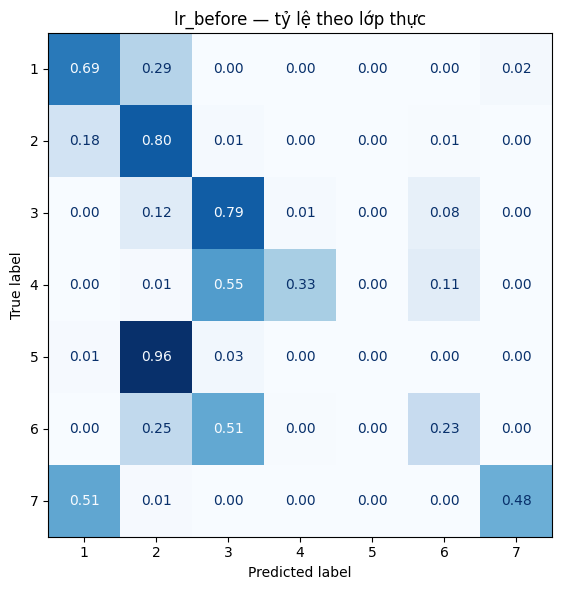

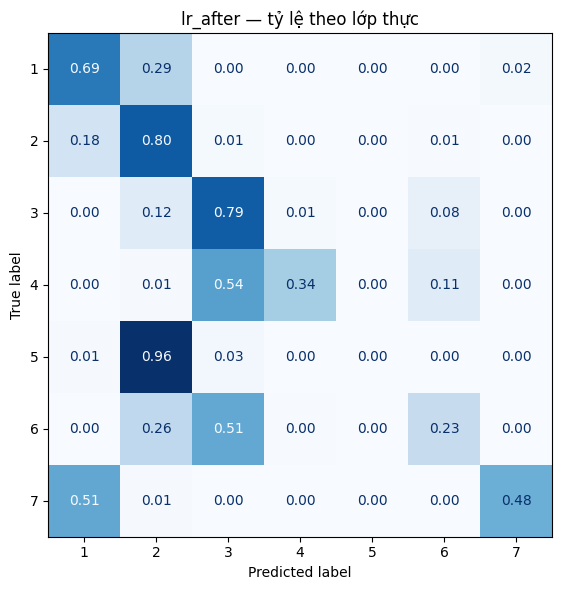

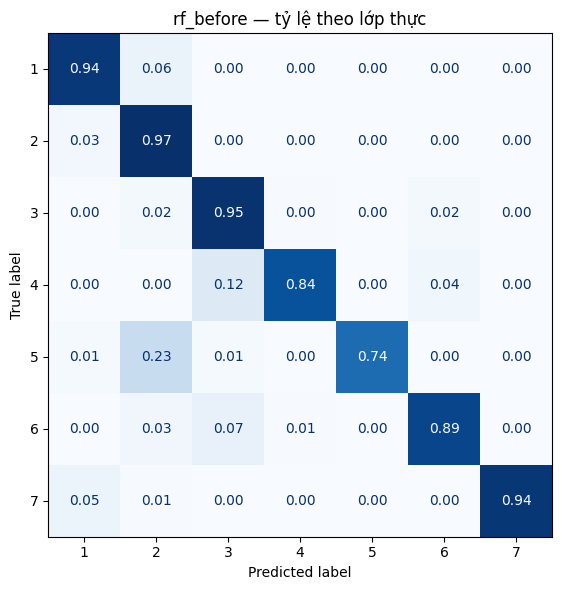

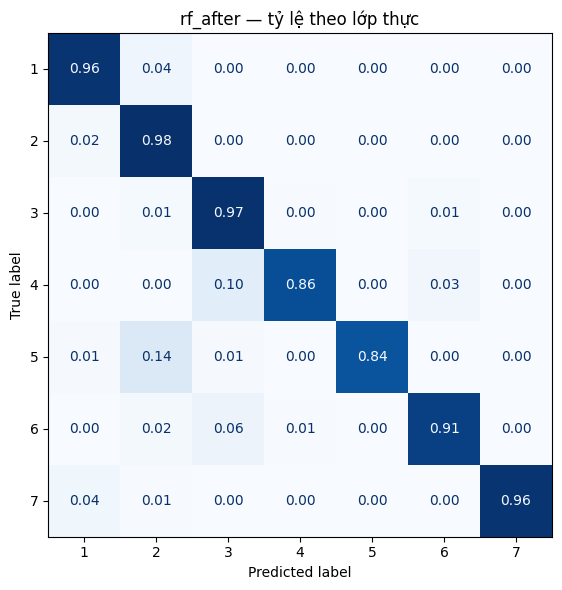

In [29]:
for name, y_pred in predictions.items():
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels,
                                            normalize='true', cmap='Blues', ax=ax,
                                            values_format='.2f', colorbar=False)
    ax.set_title(name + ' — tỷ lệ theo lớp thực')
    plt.tight_layout()
    plt.show()

### 7.5. Bảng so sánh bốn mô hình trong cùng thực nghiệm

In [30]:
fit_times = {'lr_before': fit_time_lr, 'lr_after': grid_lr.refit_time_,
             'rf_before': fit_time_rf, 'rf_after': grid_rf.refit_time_}
cv_means = {'lr_before': cv_baseline['LR']['test_f1_macro'].mean(),
            'lr_after': grid_lr.best_score_,
            'rf_before': cv_baseline['RF']['test_f1_macro'].mean(),
            'rf_after': grid_rf.best_score_}
cv_stds = {'lr_before': cv_baseline['LR']['test_f1_macro'].std(),
           'lr_after': grid_lr.cv_results_['std_test_score'][grid_lr.best_index_],
           'rf_before': cv_baseline['RF']['test_f1_macro'].std(),
           'rf_after': grid_rf.cv_results_['std_test_score'][grid_rf.best_index_]}
rows = []
for name, y_pred in predictions.items():
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, y_pred),
                 'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
                 'precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
                 'recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0),
                 'f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
                 'cv_f1_macro_mean': cv_means[name], 'cv_f1_macro_std': cv_stds[name],
                 'fit_seconds': fit_times[name], 'predict_seconds_median': predict_times[name],
                 'grid_search_total_seconds': search_time_lr if name.startswith('lr_') else search_time_rf})

comparison = pd.DataFrame(rows)
assert set(comparison['model']) == {'lr_before', 'lr_after', 'rf_before', 'rf_after'}
display(comparison.round(4))

,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,cv_f1_macro_mean,cv_f1_macro_std,fit_seconds,predict_seconds_median,grid_search_total_seconds
0,lr_before,0.7168,0.4753,0.5557,0.4753,0.5002,0.5065,0.0054,32.7235,0.0334,942.7824
1,lr_after,0.7166,0.4767,0.5549,0.4767,0.5012,0.5076,0.0047,58.7583,0.0337,942.7824
2,rf_before,0.9484,0.8959,0.9424,0.8959,0.9169,0.9070,0.0031,81.2366,2.1531,5336.2876
3,rf_after,0.9637,0.9252,0.9494,0.9252,0.9368,0.9264,0.0015,308.3845,3.3303,5336.2876


### 7.6. Điểm MI, tập biến được chọn và Feature Importance của RF


lr_before : ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Soil_Type2', 'Soil_Type4', 'Soil_Type10', 'Soil_Type12', 'Soil_Type22', 'Soil_Type23', 'Soil_Type29', 'Soil_Type38', 'Soil_Type39', 'Wilderness_Area4']
lr_after : ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Soil_Type2', 'Soil_Type4', 'Soil_Type10', 'Soil_Type12', 'Soil_Type22', 'Soil_Type23', 'Soil_Type29', 'Soil_Type38', 'Soil_Type39', 'Wilderness_Area4']
rf_before : ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Soil_Type2', 'So

,model,feature,mutual_information,selected
162,rf_after,Elevation,0.458308,True
215,rf_after,Wilderness_Area4,0.146734,True
167,rf_after,Horizontal_Distance_To_Roadways,0.088832,True
171,rf_after,Horizontal_Distance_To_Fire_Points,0.069835,True
172,rf_after,Wilderness_Area1,0.066758,True
182,rf_after,Soil_Type10,0.064289,True
164,rf_after,Slope,0.037241,True
168,rf_after,Hillshade_9am,0.032346,True
210,rf_after,Soil_Type38,0.030395,True
201,rf_after,Soil_Type29,0.029691,True


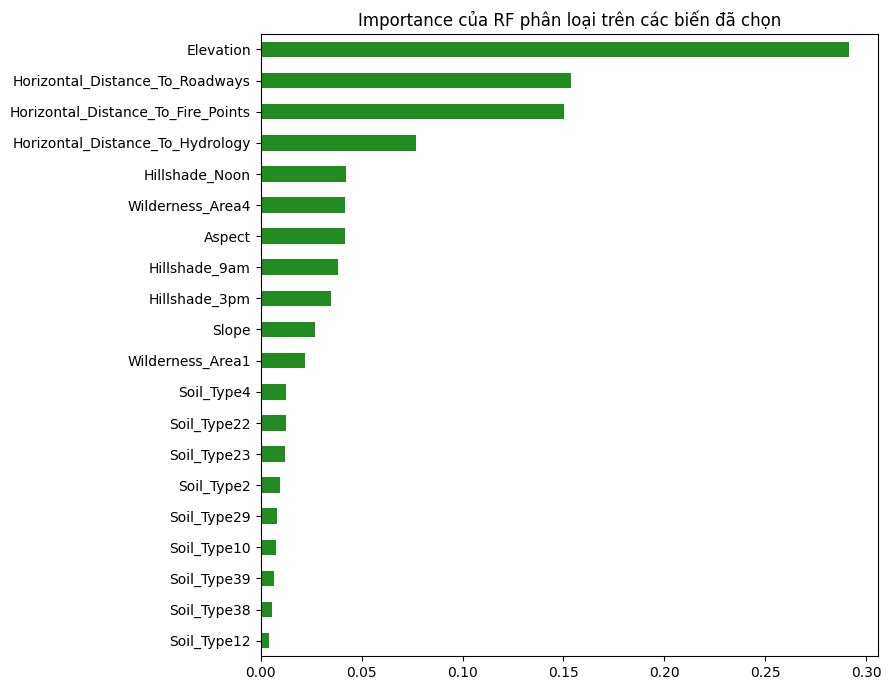

In [31]:
selected_features = {}
selector_rankings = []
for name, model in models.items():
    fitted_selector = model.named_steps['select']
    selected_features[name] = fitted_selector.get_feature_names_out().tolist()
    assert len(selected_features[name]) == TOP_K
    ranking = pd.DataFrame({
        'model': name, 'feature': features,
        'mutual_information': fitted_selector.scores_,
        'selected': fitted_selector.get_support()
    })
    selector_rankings.append(ranking)
    print(name, ':', selected_features[name])
assert all(names == selected_features['lr_before'] for names in selected_features.values())
selector_rankings = pd.concat(selector_rankings, ignore_index=True)
display(selector_rankings.query("model == 'rf_after'").sort_values('mutual_information', ascending=False))

importance = pd.Series(best_rf.named_steps['clf'].feature_importances_,
                       index=selected_features['rf_after']).sort_values(ascending=False)
importance.sort_values().plot.barh(figsize=(9, 7), color='forestgreen')
plt.title('Importance của RF phân loại trên các biến đã chọn')
plt.tight_layout()
plt.show()

### 7.7. Nhận xét kết quả
- So sánh Macro-F1, Accuracy và Recall từng lớp; không chỉ nhìn Accuracy vì dữ liệu mất cân bằng.
- So sánh trước/sau theo số thực tế. Nếu LR chọn C=1.0 và class_weight=None thì cấu hình tối ưu trùng baseline;
  điểm có thể giống nhau, còn thời gian đo hai lần fit có thể khác nhau.
- Chọn cấu hình/thuật toán theo CV, không dùng Test để tinh chỉnh lại. Importance không khẳng định nhân quả.
- Hai lưới cùng 16 cấu hình nhưng chi phí mỗi fit khác nhau; báo riêng thời gian tìm kiếm và refit cuối.
- Kết luận giới hạn ở một seed, một split ngẫu nhiên; chưa chứng minh hiệu quả tại vùng địa lý mới.
- So sánh với bản đủ 54 biến ở phụ lục lịch sử; không giả định chọn biến sẽ tăng điểm.
- fit_seconds gồm selector và có thể hưởng cache; không so trực tiếp với lần chạy cũ.
- Dùng lại holdout cũ để đối chiếu mô tả; không chỉnh TOP_K theo Test.


In [32]:
cv_selection = pd.DataFrame({'model': ['lr_after', 'rf_after'],
                              'cv_f1_macro': [grid_lr.best_score_, grid_rf.best_score_]})
selected = cv_selection.sort_values('cv_f1_macro', ascending=False).iloc[0]
print('Mô hình được chọn theo CV:', selected['model'])
display(cv_selection)

Mô hình được chọn theo CV: rf_after


,model,cv_f1_macro
0,lr_after,0.507573
1,rf_after,0.926392


## Phụ lục. So sánh lịch sử và lưu kết quả riêng
Bảng lịch sử là snapshot output đã lưu của `LR_RF_Covertype.ipynb`, làm tròn 4 chữ số.
Đây là các lần chạy khác nhau; chưa xác thực fingerprint hoặc môi trường của kết quả lịch sử.
Không gộp điểm lịch sử thành kết quả CV của thực nghiệm mới. Không dùng Test để chọn lại TOP_K.
Thời gian không so trực tiếp vì cache và môi trường có thể khác.


In [33]:
historical = pd.DataFrame([{'model': 'lr_before', 'accuracy': 0.7233, 'balanced_accuracy': 0.5089, 'precision_macro': 0.591, 'recall_macro': 0.5089, 'f1_macro': 0.53, 'cv_f1_macro_mean': 0.5325, 'cv_f1_macro_std': 0.0043, 'fit_seconds': 89.948, 'predict_seconds_median': 0.2277, 'grid_search_total_seconds': 2637.795}, {'model': 'lr_after', 'accuracy': 0.7235, 'balanced_accuracy': 0.5103, 'precision_macro': 0.5909, 'recall_macro': 0.5103, 'f1_macro': 0.5312, 'cv_f1_macro_mean': 0.5343, 'cv_f1_macro_std': 0.0039, 'fit_seconds': 103.2244, 'predict_seconds_median': 0.235, 'grid_search_total_seconds': 2637.795}, {'model': 'rf_before', 'accuracy': 0.9538, 'balanced_accuracy': 0.9064, 'precision_macro': 0.9466, 'recall_macro': 0.9064, 'f1_macro': 0.9249, 'cv_f1_macro_mean': 0.9117, 'cv_f1_macro_std': 0.0003, 'fit_seconds': 167.8231, 'predict_seconds_median': 4.7968, 'grid_search_total_seconds': 12719.5829}, {'model': 'rf_after', 'accuracy': 0.9681, 'balanced_accuracy': 0.9337, 'precision_macro': 0.9541, 'recall_macro': 0.9337, 'f1_macro': 0.9435, 'cv_f1_macro_mean': 0.9328, 'cv_f1_macro_std': 0.0008, 'fit_seconds': 789.6306, 'predict_seconds_median': 7.8812, 'grid_search_total_seconds': 12719.5829}])
historical['source'] = 'historical_saved_output_rounded_4dp'
historical['n_features'] = 54
historical['source_notebook_sha256'] = 'f39440f338308e724679f3c3b5528a3cbf8c7441243511297c0c1f96307a3caa'
current = comparison.copy()
current['source'] = 'current_feature_selection_run'
current['n_features'] = TOP_K
historical_comparison = pd.concat([historical, current], ignore_index=True)
display(historical_comparison[['model', 'source', 'n_features', 'accuracy', 'f1_macro',
                              'cv_f1_macro_mean']].round(4))


,model,source,n_features,accuracy,f1_macro,cv_f1_macro_mean
0,lr_before,historical_saved_output_rounded_4dp,54,0.7233,0.5300,0.5325
1,lr_after,historical_saved_output_rounded_4dp,54,0.7235,0.5312,0.5343
2,rf_before,historical_saved_output_rounded_4dp,54,0.9538,0.9249,0.9117
3,rf_after,historical_saved_output_rounded_4dp,54,0.9681,0.9435,0.9328
4,lr_before,current_feature_selection_run,20,0.7168,0.5002,0.5065
5,lr_after,current_feature_selection_run,20,0.7166,0.5012,0.5076
6,rf_before,current_feature_selection_run,20,0.9484,0.9169,0.9070
7,rf_after,current_feature_selection_run,20,0.9637,0.9368,0.9264


In [34]:
import hashlib
import json
import platform
import sys
import joblib

h = hashlib.sha256()
h.update(np.ascontiguousarray(X, dtype=np.float32).tobytes())
h.update(np.ascontiguousarray(y, dtype=np.int8).tobytes())
h.update(json.dumps(features, ensure_ascii=False).encode('utf-8'))
fingerprint = h.hexdigest()
# Fingerprint dùng tên cột UCI hiện tại; không so với tên cột sklearn của phiên cũ.
split_hash = hashlib.sha256(train_idx.tobytes() + test_idx.tobytes()).hexdigest()
fold_id = np.full(len(y_train), -1, dtype=np.int8)
for fold, (_, valid_pos) in enumerate(cv_splits):
    fold_id[valid_pos] = fold
fold_hash = hashlib.sha256(fold_id.tobytes()).hexdigest()
print('Thư mục kết quả:', OUT.resolve())

Thư mục kết quả: /content/Covertype_RF_LR_MI/runs/20261114_131410_269979


In [35]:
environment = {'run_id': RUN_ID, 'output_dir': str(OUT.resolve()), 'python': sys.version,
               'platform': platform.platform(), 'sklearn': sklearn.__version__,
               'numpy': np.__version__, 'pandas': pd.__version__, 'seed': SEED,
               'test_size': 0.2, 'cv_folds': N_SPLITS, 'thread_budget': N_JOBS,
               'run_lr': True, 'run_rf': True, 'selection_top_k': TOP_K,
               'selection_method': 'mutual_information',
               'selector_params': {'k': TOP_K, 'n_neighbors': 3, 'random_state': SEED,
                                   'n_jobs': N_JOBS, 'discrete_features': discrete_mask.tolist()}, 'data_fingerprint': fingerprint,
               'split_sha256': split_hash, 'fold_sha256': fold_hash,
               'lr_param_grid': param_grid_lr, 'rf_param_grid': param_grid_rf}
comparison['run_id'] = RUN_ID
comparison['source'] = 'current_run'
comparison['sklearn_version'] = sklearn.__version__
comparison['data_fingerprint'] = fingerprint
comparison['split_sha256'] = split_hash
comparison['fold_sha256'] = fold_hash
comparison.to_csv(OUT / 'same_experiment_comparison.csv', index=False, encoding='utf-8-sig')
comparison.to_csv(OUT / 'current_run_results.csv', index=False, encoding='utf-8-sig')

np.savez_compressed(OUT / 'shared_split.npz', train_idx=train_idx, test_idx=test_idx,
                    seed=SEED, test_size=0.2, fingerprint=fingerprint)
pd.DataFrame({'source_row_id': train_idx, 'label': y_train.to_numpy(),
              'validation_fold': fold_id}).to_csv(OUT / 'train_cv_folds.csv', index=False)
df_grid_lr.to_csv(OUT / 'lr_grid_search_results.csv', index=False)
df_grid_rf.to_csv(OUT / 'grid_search_results.csv', index=False)

In [36]:
for name, model in models.items():
    joblib.dump({'model': model, 'feature_names': features, 'selected_features': selected_features[name], 'data_fingerprint': fingerprint,
                 'split_sha256': split_hash, 'fold_sha256': fold_hash,
                 'sklearn_version': sklearn.__version__}, OUT / f'{name}.joblib', compress=3)
    pd.DataFrame({'source_row_id': test_idx, 'y_true': y_test.to_numpy(),
                  'y_pred': predictions[name]}).to_csv(OUT / f'{name}_predictions.csv', index=False)
    report = classification_report(y_test, predictions[name], labels=labels,
                                    target_names=class_names, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT / f'{name}_classification_report.csv', encoding='utf-8-sig')

historical_comparison.to_csv(OUT / 'historical_vs_feature_selection.csv', index=False, encoding='utf-8-sig')

selector_rankings.to_csv(OUT / 'mi_feature_scores.csv', index=False)
importance.rename('classification_importance').to_csv(OUT / 'rf_selected_feature_importance.csv')

metadata = {
    'environment.json': environment,
    'data_manifest.json': {'source': 'ucimlrepo.fetch_ucirepo(id=31)', 'feature_names': features, 'selected_features': selected_features['rf_after'],
                           'n_samples': len(df), 'n_features': len(features)},
    'lr_best_params.json': grid_lr.best_params_,
    'best_params.json': grid_rf.best_params_,
    'comparison_status.json': {'run_id': RUN_ID, 'complete': True},
    'selected_model_by_cv.json': {'model': selected['model'], 'selection_metric': 'CV f1_macro',
                                 'cv_f1_macro': float(selected['cv_f1_macro']), 'run_id': RUN_ID}
}
for filename, value in metadata.items():
    (OUT / filename).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
(RESULTS_ROOT / 'latest_run.json').write_text(json.dumps({
    'run_id': RUN_ID, 'output_dir': str(OUT.resolve()), 'run_lr': True, 'run_rf': True}, indent=2), encoding='utf-8')
print('Đã lưu bốn Pipeline và bảng so sánh:', OUT.resolve())


Đã lưu bốn Pipeline và bảng so sánh: /content/Covertype_RF_LR_MI/runs/20261114_131410_269979
